In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Geometry (micrometres)
L = 500.0           # Horizontal length of biofilm
h0 = 40.0           # Baseline thickness
nx = 501            # Number of horizontal sampling points

x = np.linspace(0, L, nx)

# Random number generator
rng = np.random.default_rng(42)

The height profile is randomized using the sum of gaussian function, $f(x)$, where
$$
f(x) = a\times e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)}
$$
Where $a$, $\mu$, and $\sigma$ is the amplitude, center, and spread respectively.

To generate the random profile, we take the sum of gaussian functions.
$$
\sum_{i=1}^{N}f_i(x)=\sum_{i=1}^{N}a_i\times e^{-\frac{1}{2}\left(\frac{x-\mu_{i}}{\sigma_{i}}\right)}
$$
Where $a_{i}$, $\mu_{i}$, and $\sigma_{i}$ are randomly generated values within a given range.

In [79]:
import sys
from pathlib import Path

# Add project root to Python's import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.stochastic_geometry import random_height_profile
from src.layer_mesh import build_layer_mesh

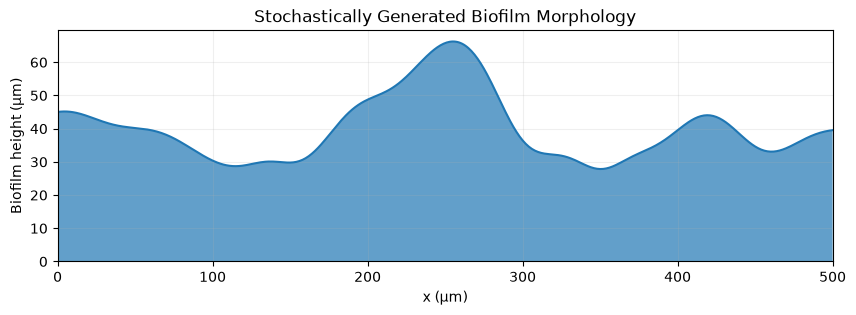

Minimum height: 27.85 μm
Maximum height: 66.26 μm
Mean height: 40.00 μm
All heights positive: True
Reproducible: True


In [30]:
h = random_height_profile(x)

plt.figure(figsize=(10, 3))

plt.fill_between(x, 0, h, alpha=0.7)
plt.plot(x, h, linewidth=1.5)

plt.xlabel("x (μm)")
plt.ylabel("Biofilm height (μm)")
plt.title("Stochastically Generated Biofilm Morphology")

plt.xlim(0, L)
plt.ylim(bottom=0)
plt.grid(alpha=0.2)

plt.show()

print(f"Minimum height: {h.min():.2f} μm")
print(f"Maximum height: {h.max():.2f} μm")
print(f"Mean height: {h.mean():.2f} μm")
print(f"All heights positive: {np.all(h > 0)}")

h1 = random_height_profile(x, h0, rng=np.random.default_rng(42))
h2 = random_height_profile(x, h0, rng=np.random.default_rng(42))

print("Reproducible:", np.array_equal(h1, h2))

In [95]:
# Number of vertical intervals
ny = 60

# Normalized vertical coordinates
# Note: Since there are ny intervals, there are ny+1 coordinates
eta = np.linspace(0, 1, ny + 1)

# Construct 2D coordinate arrays
# 1. array of x coordinates
X = np.broadcast_to(x[None, :], (ny + 1, nx))
# 2. array of y coordinates (absolute, in original units)
#    We do this by the value of each column normalised column
#    (in eta) by their respective maximum height as initialised
#    in h
Y = eta[:, None] * h[None, :]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (61, 501)
Y shape: (61, 501)


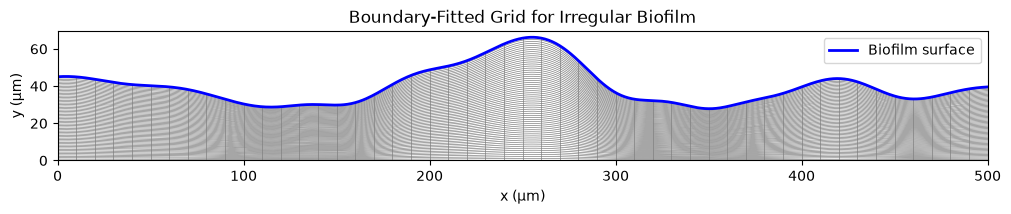

Bottom boundary correct: True
Top boundary correct: True
Positive vertical spacing: True


In [96]:
fig, ax = plt.subplots(figsize=(12, 3))

# Plot horizontal grid lines
for i in range(ny + 1):
    ax.plot(X[i, :], Y[i, :], color="gray", linewidth=0.5)

# Plot vertical grid lines (sample every 10th column for clarity)
for j in range(0, nx, 10):
    ax.plot(X[:, j], Y[:, j], color="gray", linewidth=0.5)

# Highlight the biofilm surface
ax.plot(x, h, color="blue", linewidth=2, label="Biofilm surface")

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Boundary-Fitted Grid for Irregular Biofilm")
ax.set_aspect("equal")
ax.legend()

ax.set_xlim(0, L)
ax.set_ylim(bottom=0)

plt.show()

# Bottom row must lie on the substrate
print("Bottom boundary correct:", np.allclose(Y[0, :], 0))

# Top row must match the biofilm surface
print("Top boundary correct:", np.allclose(Y[-1, :], h))

# Every vertical column must increase upward
print("Positive vertical spacing:", np.all(np.diff(Y, axis=0) > 0))

In [97]:
# Number of grid points
n_rows, n_cols = X.shape

# Flatten the coordinate arrays into a list of (x, y) pairs
points = np.column_stack([ # column stack used to pair X with respective Y.
    X.ravel(), # row-priority flattening of 2D coordinate arrays.
    Y.ravel()
])

# Define a helper function to help us search for a node in the flattened
# array given the coordinates (i,j), where (i,j) = (x,y) = (col, row)
def node_id(i, j):
    return j * n_cols + i

print("Number of nodes:", len(points))
print("Shape:", points.shape)
print("First five nodes:")
print(points[:5])

Number of nodes: 30561
Shape: (30561, 2)
First five nodes:
[[0. 0.]
 [1. 0.]
 [2. 0.]
 [3. 0.]
 [4. 0.]]


In [98]:
triangles = []

for j in range(n_rows - 1):
    for i in range(n_cols - 1):

        # Four corners of the current quadrilateral
        n00 = node_id(i, j)          # bottom-left
        n10 = node_id(i + 1, j)      # bottom-right
        n01 = node_id(i, j + 1)      # top-left
        n11 = node_id(i + 1, j + 1)  # top-right

        # Divide the quadrilateral into two triangles
        triangles.append([n00, n10, n11])
        triangles.append([n00, n11, n01])

triangles = np.array(triangles, dtype=int)

print("Number of triangles:", len(triangles))
print("Shape:", triangles.shape)

Number of triangles: 60000
Shape: (60000, 3)


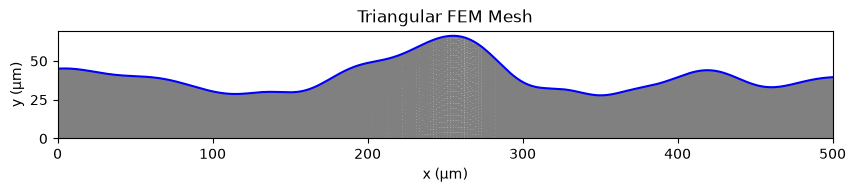

Minimum signed area: 0.2320777968476193 μm²
Number of non-positive areas: 0
Mesh area:    20000.0000 μm²
Profile area: 20000.0000 μm²
Relative error: 0.0


In [99]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.triplot(
    points[:, 0],
    points[:, 1],
    triangles,
    linewidth=0.4,
    color="gray"
)

ax.plot(x, h, color="blue", linewidth=1.5)

ax.set_xlim(0, L)
ax.set_ylim(bottom=0)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Triangular FEM Mesh")

ax.set_aspect("equal")

plt.show()

# Coordinates of the three vertices of every triangle
P = points[triangles]  # Shape: (n_triangles, 3, 2)

# Two edge vectors originating from the first vertex
AB = P[:, 1] - P[:, 0]
AC = P[:, 2] - P[:, 0]

# Signed triangle areas
signed_areas = 0.5 * (
    AB[:, 0] * AC[:, 1]
    - AB[:, 1] * AC[:, 0]
)

print("Minimum signed area:", signed_areas.min(), "μm²")
print("Number of non-positive areas:", np.sum(signed_areas <= 0))

area_mesh = signed_areas.sum()

area_profile = np.trapezoid(h, x)

print(f"Mesh area:    {area_mesh:.4f} μm²")
print(f"Profile area: {area_profile:.4f} μm²")

print(
    "Relative error:",
    abs(area_mesh - area_profile) / area_profile
)

# Defining the Grid

In [100]:
# Grid dimensions (μm)
L = 500.0
H_domain = 200.0

# Number of cells
grid_nx = 500
grid_ny = 200

# Physical boundaries
x_min, x_max = 0.0, L
y_min, y_max = 0.0, H_domain

# Cell dimensions
dx = (x_max - x_min) / grid_nx
dy = (y_max - y_min) / grid_ny

# Cell-centre coordinates
x_centres = x_min + (np.arange(grid_nx) + 0.5) * dx
y_centres = y_min + (np.arange(grid_ny) + 0.5) * dy

# Biofilm height at each horizontal cell centre
# Note: this essentialy predicts what the h value
# should be at point x
h_centres = np.interp(x_centres, x, h)

# Construct occupancy grid
# Note:
# y_centres[:, None].shape = (j,1)
# h_centres[None, :].shape = (1,i)
# occupancy.shape = (j,i)
occupancy = y_centres[:, None] <= h_centres[None, :]
print(occupancy.shape)

(200, 500)


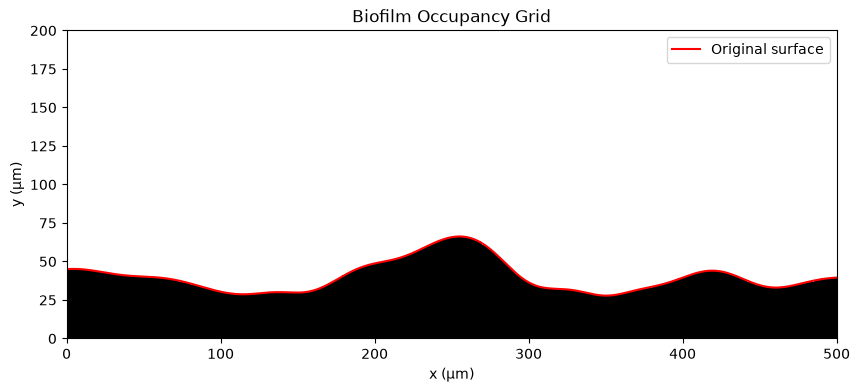

=== Area Verification ===
Height profile: 20000.00 μm²
FEM mesh:       20000.00 μm²
Occupancy grid: 19994.00 μm²

FEM relative error:  0.000000%
Grid relative error: 0.030000%


In [101]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.imshow(
    occupancy,
    origin="lower",
    extent=[x_min, x_max, y_min, y_max],
    aspect="equal",
    interpolation="nearest",
    cmap="Greys"
)

# Overlay original biofilm surface
ax.plot(x, h, color="red", linewidth=1.5, label="Original surface")

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Biofilm Occupancy Grid")

ax.legend()
plt.show()

print("=== Area Verification ===")

area_profile = np.trapezoid(h, x)
area_grid = occupancy.sum() * dx * dy

print(f"Height profile: {area_profile:.2f} μm²")
print(f"FEM mesh:       {area_mesh:.2f} μm²")
print(f"Occupancy grid: {area_grid:.2f} μm²")

error_mesh = abs(area_mesh - area_profile) / area_profile
error_grid = abs(area_grid - area_profile) / area_profile

print(f"\nFEM relative error:  {error_mesh:.6%}")
print(f"Grid relative error: {error_grid:.6%}")

# Saving the Occupancy Grid

In [102]:
from pathlib import Path

# Create output directory
output_dir = Path("../outputs/data")
output_dir.mkdir(parents=True, exist_ok=True)

# Conversion factor
um = 1e-6

# Save geometry and metadata
np.savez_compressed(
    output_dir / "biofilm_sample_001.npz",

    # Biofilm occupancy
    solid_mask=occupancy.astype(np.uint8),

    # Grid dimensions (SI units)
    dx_m=dx * um,
    dy_m=dy * um,

    # Domain origin (SI units)
    origin_m=np.array([x_min, y_min]) * um,

    # Original height profile
    x_profile_m=x * um,
    h_profile_m=h * um,

    # Metadata
    seed=42,
    axis_order="yx",
    source="stochastic_gaussian_profile"
)

print("Saved:", output_dir / "biofilm_sample_001.npz")

Saved: ../outputs/data/biofilm_sample_001.npz


# Reconstructing Grid from Saved Data

Loaded mask shape: (200, 500)
Cell width: 1e-06 m
Cell height: 1e-06 m
Origin: [0. 0.]
Occupancy identical: True
dx identical: True
dy identical: True
Height profile identical: True
Axis convention correct: True
Original area: 1.99940000e-08 m²
Loaded area:   1.99940000e-08 m²
Area preserved: True


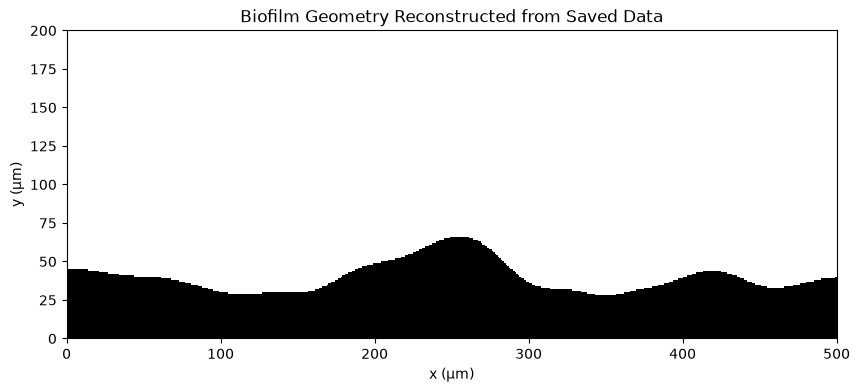

In [103]:
# Load the saved file
data = np.load(
    output_dir / "biofilm_sample_001.npz",
    allow_pickle=False
)

# Retrieve saved variables
loaded_mask = data["solid_mask"].astype(bool)

loaded_dx = float(data["dx_m"])
loaded_dy = float(data["dy_m"])

loaded_origin = data["origin_m"]

print("Loaded mask shape:", loaded_mask.shape)
print("Cell width:", loaded_dx, "m")
print("Cell height:", loaded_dy, "m")
print("Origin:", loaded_origin)

print(
    "Occupancy identical:",
    np.array_equal(occupancy, loaded_mask)
)

print(
    "dx identical:",
    np.isclose(dx * um, loaded_dx)
)

print(
    "dy identical:",
    np.isclose(dy * um, loaded_dy)
)

print(
    "Height profile identical:",
    np.array_equal(h * um, data["h_profile_m"])
)

print(
    "Axis convention correct:",
    str(data["axis_order"]) == "yx"
)

# Number of cells
loaded_ny, loaded_nx = loaded_mask.shape

# Reconstruct cell-centre coordinates (metres)
x_loaded = (
    loaded_origin[0]
    + (np.arange(loaded_nx) + 0.5) * loaded_dx
)

y_loaded = (
    loaded_origin[1]
    + (np.arange(loaded_ny) + 0.5) * loaded_dy
)

# Visualize reconstructed geometry
fig, ax = plt.subplots(figsize=(11, 4))

ax.imshow(
    loaded_mask,
    origin="lower",
    extent=[
        loaded_origin[0] / um,
        (loaded_origin[0] + loaded_nx * loaded_dx) / um,
        loaded_origin[1] / um,
        (loaded_origin[1] + loaded_ny * loaded_dy) / um
    ],
    aspect="equal",
    cmap="Greys",
    interpolation="nearest"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Biofilm Geometry Reconstructed from Saved Data")

plt.show

loaded_area = loaded_mask.sum() * loaded_dx * loaded_dy

print(f"Original area: {area_grid * um**2:.8e} m²")
print(f"Loaded area:   {loaded_area:.8e} m²")

print(
    "Area preserved:",
    np.isclose(
        area_grid * um**2,
        loaded_area
    )
)

# Regulated vs Unregulated

In [104]:
def geometry_metrics(x, h):
    """
    Calculate geometric properties of a continuous biofilm layer.

    x, h: coordinates in micrometres.
    """

    slope = np.gradient(h, x)

    return {
        "mean_height": np.trapezoid(h, x) / (x[-1] - x[0]),
        "max_height": h.max(),
        "min_height": h.min(),
        "area": np.trapezoid(h, x),
        "rms_slope": np.sqrt(np.mean(slope**2))
    }

Unregulated mean height: 79.97 μm
Regulated mean height:   39.98 μm


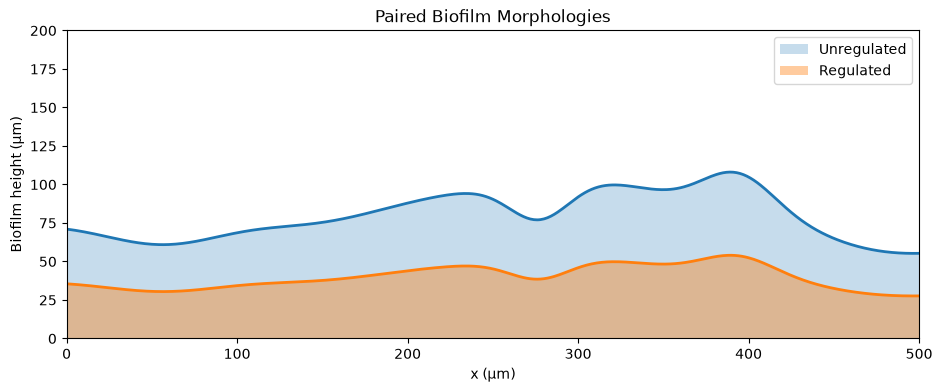

Metric                   Unregulated       Regulated
mean_height                   80.000          40.000
max_height                   108.063          54.031
min_height                    55.270          27.635
area                       40000.000       20000.000
rms_slope                      0.387           0.193


In [105]:
# Hypothetical regulation parameters
alpha = 0.5

# Reproduce the original morphology
seed = 42

h_unregulated = random_height_profile(
    x,
    rng=np.random.default_rng(seed)
)

# Apply hypothetical thickness reduction
h_regulated = alpha * h_unregulated

print(f"Unregulated mean height: {h_unregulated.mean():.2f} μm")
print(f"Regulated mean height:   {h_regulated.mean():.2f} μm")

fig, ax = plt.subplots(figsize=(11, 4))

ax.fill_between(
    x, 0, h_unregulated,
    alpha=0.25,
    label="Unregulated"
)

ax.plot(
    x, h_unregulated,
    linewidth=2
)

ax.fill_between(
    x, 0, h_regulated,
    alpha=0.4,
    label="Regulated"
)

ax.plot(
    x, h_regulated,
    linewidth=2
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("Biofilm height (μm)")
ax.set_title("Paired Biofilm Morphologies")

ax.set_xlim(0, L)
ax.set_ylim(0, H_domain)

ax.legend()
plt.show()

metrics_unregulated = geometry_metrics(x, h_unregulated)
metrics_regulated = geometry_metrics(x, h_regulated)

print(f"{'Metric':<20} {'Unregulated':>15} {'Regulated':>15}")

for key in metrics_unregulated:
    print(
        f"{key:<20} "
        f"{metrics_unregulated[key]:>15.3f} "
        f"{metrics_regulated[key]:>15.3f}"
    )

# Generating Random Biofilms

In [106]:
N_FEATURES = 10

profiles = {}

for seed in range(20):
    profiles[seed] = random_height_profile(
        x,
        mean_height=80.0,
        roughness=15.0,
        n_features=N_FEATURES,
        min_height=5.0,
        rng=np.random.default_rng(seed)
    )

paired_profiles = {
    seed: {
        "unregulated": h,
        "regulated": 0.5 * h
    }
    for seed, h in profiles.items()
}

print(f"Generated {len(profiles)} biofilm profiles.")

Generated 20 biofilm profiles.


In [107]:
for seed, h_sample in profiles.items():

    mean_h = np.trapezoid(h_sample, x) / (x[-1] - x[0])

    rms_h = np.sqrt(
        np.trapezoid((h_sample - mean_h)**2, x)
        / (x[-1] - x[0])
    )

    assert np.isclose(mean_h, MEAN_HEIGHT)
    assert np.isclose(rms_h, ROUGHNESS)
    assert h_sample.min() >= MIN_HEIGHT

print("All 20 profiles passed geometric verification.")

All 20 profiles passed geometric verification.


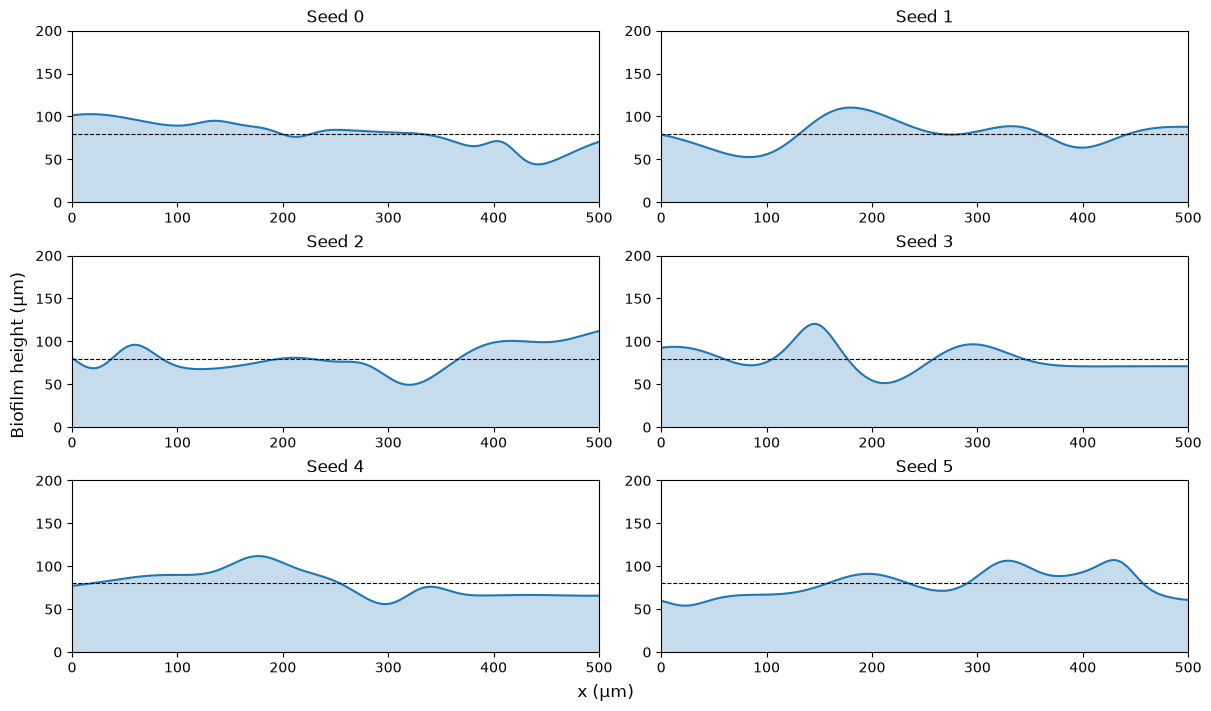

In [108]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 7),
    constrained_layout=True
)

for seed, ax in enumerate(axes.flat):

    h_sample = profiles[seed]

    ax.fill_between(x, 0, h_sample, alpha=0.25)
    ax.plot(x, h_sample)

    ax.axhline(
        MEAN_HEIGHT,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(f"Seed {seed}")
    ax.set_xlim(0, L)
    ax.set_ylim(0, H_domain)

fig.supxlabel("x (μm)")
fig.supylabel("Biofilm height (μm)")

plt.show()

# Introducing Paired profiles

## 1. Reducing Thickness by 1/2

In [109]:
ALPHA = 0.5

paired_profiles = {}

for seed, h_unregulated in profiles.items():

    h_regulated = ALPHA * h_unregulated

    paired_profiles[seed] = {
        "unregulated": h_unregulated,
        "regulated": h_regulated
    }

for seed, pair in paired_profiles.items():

    h_u = pair["unregulated"]
    h_r = pair["regulated"]

    # Regulated biofilm must be thinner everywhere
    assert np.all(h_r <= h_u)

    # Mean thickness should scale by alpha
    mean_u = np.trapezoid(h_u, x) / L
    mean_r = np.trapezoid(h_r, x) / L

    assert np.isclose(mean_r, ALPHA * mean_u)

    # Both profiles must remain positive
    assert h_r.min() > 0

print("All paired profiles passed verification.")

for seed in range(5):

    h_u = paired_profiles[seed]["unregulated"]
    h_r = paired_profiles[seed]["regulated"]

    m_u = geometry_metrics(x, h_u)
    m_r = geometry_metrics(x, h_r)

    print(f"\nSeed {seed}")

    print(
        f"Mean height: "
        f"{m_u['mean_height']:.2f} → "
        f"{m_r['mean_height']:.2f} μm"
    )

    print(
        f"Maximum height: "
        f"{m_u['max_height']:.2f} → "
        f"{m_r['max_height']:.2f} μm"
    )

    print(
        f"Cross-sectional area: "
        f"{m_u['area']:.2f} → "
        f"{m_r['area']:.2f} μm²"
    )

All paired profiles passed verification.

Seed 0
Mean height: 80.00 → 40.00 μm
Maximum height: 102.70 → 51.35 μm
Cross-sectional area: 40000.00 → 20000.00 μm²

Seed 1
Mean height: 80.00 → 40.00 μm
Maximum height: 110.34 → 55.17 μm
Cross-sectional area: 40000.00 → 20000.00 μm²

Seed 2
Mean height: 80.00 → 40.00 μm
Maximum height: 111.95 → 55.98 μm
Cross-sectional area: 40000.00 → 20000.00 μm²

Seed 3
Mean height: 80.00 → 40.00 μm
Maximum height: 120.36 → 60.18 μm
Cross-sectional area: 40000.00 → 20000.00 μm²

Seed 4
Mean height: 80.00 → 40.00 μm
Maximum height: 111.86 → 55.93 μm
Cross-sectional area: 40000.00 → 20000.00 μm²


In [110]:
# Checking if slopes are reasonable

for seed, pair in paired_profiles.items():

    for condition, h_sample in pair.items():

        slope = np.gradient(h_sample, x)

        print(
            f"Seed {seed:2d} | "
            f"{condition:11s} | "
            f"Max |slope| = {np.max(np.abs(slope)):.3f}"
        )

Seed  0 | unregulated | Max |slope| = 1.171
Seed  0 | regulated   | Max |slope| = 0.586
Seed  1 | unregulated | Max |slope| = 1.010
Seed  1 | regulated   | Max |slope| = 0.505
Seed  2 | unregulated | Max |slope| = 1.111
Seed  2 | regulated   | Max |slope| = 0.556
Seed  3 | unregulated | Max |slope| = 1.741
Seed  3 | regulated   | Max |slope| = 0.870
Seed  4 | unregulated | Max |slope| = 0.755
Seed  4 | regulated   | Max |slope| = 0.377
Seed  5 | unregulated | Max |slope| = 1.371
Seed  5 | regulated   | Max |slope| = 0.686
Seed  6 | unregulated | Max |slope| = 0.566
Seed  6 | regulated   | Max |slope| = 0.283
Seed  7 | unregulated | Max |slope| = 0.935
Seed  7 | regulated   | Max |slope| = 0.467
Seed  8 | unregulated | Max |slope| = 0.598
Seed  8 | regulated   | Max |slope| = 0.299
Seed  9 | unregulated | Max |slope| = 1.258
Seed  9 | regulated   | Max |slope| = 0.629
Seed 10 | unregulated | Max |slope| = 0.711
Seed 10 | regulated   | Max |slope| = 0.355
Seed 11 | unregulated | Max |slo

In [111]:
from src.layer_mesh import build_layer_mesh
from src.mesh_quality import evaluate_mesh_quality

mesh_results = []

for seed, pair in paired_profiles.items():

    for condition, h_sample in pair.items():

        points_i, triangles_i, boundaries_i = build_layer_mesh(
            x,
            h_sample,
            ny=20
        )

        q = evaluate_mesh_quality(points_i, triangles_i)

        mesh_results.append({
            "seed": seed,
            "condition": condition,
            "min_angle": q["min_angle"].min(),
            "max_edge_ratio": q["aspect_ratio"].max(),
            "inverted": np.sum(q["signed_area"] <= 0)
        })

for r in mesh_results:
    print(
        f"Seed {r['seed']:2d} | "
        f"{r['condition']:11s} | "
        f"Min angle = {r['min_angle']:6.2f}° | "
        f"Max edge ratio = {r['max_edge_ratio']:6.2f} | "
        f"Inverted = {r['inverted']}"
    )

Seed  0 | unregulated | Min angle =  10.86° | Max edge ratio =   5.28 | Inverted = 0
Seed  0 | regulated   | Min angle =  20.99° | Max edge ratio =   2.79 | Inverted = 0
Seed  1 | unregulated | Min angle =   9.79° | Max edge ratio =   5.67 | Inverted = 0
Seed  1 | regulated   | Min angle =  19.04° | Max edge ratio =   3.00 | Inverted = 0
Seed  2 | unregulated | Min angle =   9.67° | Max edge ratio =   5.77 | Inverted = 0
Seed  2 | regulated   | Min angle =  18.81° | Max edge ratio =   3.07 | Inverted = 0
Seed  3 | unregulated | Min angle =   8.23° | Max edge ratio =   6.18 | Inverted = 0
Seed  3 | regulated   | Min angle =  16.13° | Max edge ratio =   3.29 | Inverted = 0
Seed  4 | unregulated | Min angle =   9.67° | Max edge ratio =   5.75 | Inverted = 0
Seed  4 | regulated   | Min angle =  18.83° | Max edge ratio =   3.05 | Inverted = 0
Seed  5 | unregulated | Min angle =   9.32° | Max edge ratio =   5.54 | Inverted = 0
Seed  5 | regulated   | Min angle =  18.17° | Max edge ratio =   

In [112]:
from src.layer_mesh import build_layer_mesh
from src.mesh_quality import evaluate_mesh_quality

# Select one representative geometry
h_sample = paired_profiles[0]["unregulated"]

for ny_test in [20, 40, 60, 80]:

    points_test, triangles_test, _ = build_layer_mesh(
        x,
        h_sample,
        ny=ny_test
    )

    q = evaluate_mesh_quality(points_test, triangles_test)

    print(
        f"ny={ny_test:3d} | "
        f"Triangles={len(triangles_test):6d} | "
        f"Min angle={q['min_angle'].min():6.2f}° | "
        f"Max edge ratio={q['aspect_ratio'].max():5.2f}"
    )

ny= 20 | Triangles= 20000 | Min angle= 10.86° | Max edge ratio= 5.28
ny= 40 | Triangles= 40000 | Min angle= 19.47° | Max edge ratio= 2.83
ny= 60 | Triangles= 60000 | Min angle= 15.27° | Max edge ratio= 2.50
ny= 80 | Triangles= 80000 | Min angle= 12.53° | Max edge ratio= 3.03


In [113]:
# Select one stochastic biofilm
h_sample = paired_profiles[0]["unregulated"]

# Generate triangular mesh
points_um, triangles, boundaries = build_layer_mesh(
    x,
    h_sample,
    ny=60
)

print("Nodes:", len(points_um))
print("Triangles:", len(triangles))

Nodes: 30561
Triangles: 60000


# Preparing for FEM

In [115]:
from src.layer_mesh import build_layer_mesh

# Select one stochastic biofilm
h_sample = paired_profiles[0]["unregulated"]

# Generate triangular mesh
points_um, triangles, boundaries = build_layer_mesh(
    x,
    h_sample,
    ny=60
)

print("Nodes:", len(points_um))
print("Triangles:", len(triangles))

UM = 1e-6

points_m = points_um * UM

print("First five nodes (m):")
print(points_m[:5])

Nodes: 30561
Triangles: 60000
First five nodes (m):
[[0.e+00 0.e+00]
 [1.e-06 0.e+00]
 [2.e-06 0.e+00]
 [3.e-06 0.e+00]
 [4.e-06 0.e+00]]


In [116]:
from sfepy.discrete.fem import Mesh

mesh = Mesh.from_data(
    "stochastic_biofilm",
    points_m,
    None,
    [triangles.astype(np.int32)],
    [np.zeros(len(triangles), dtype=np.int32)],
    ["2_3"]
)

print(mesh)

install jax and jaxlib to use terms_jax.py!
sfepy: WARNING: module /Users/zewei/miniconda3/envs/biofilm-fem/lib/python3.13/site-packages/sfepy/terms/terms_jax.py cannot be imported!
sfepy: reason:
 No module named 'jax'
Mesh:stochastic_biofilm
  _coors:
    (30561, 2) array of float64
  cmesh:
    CMesh: n_coor: 30561, dim 2, tdim: 2, n_el 60000
  cmesh_tdim:
    list: [None, None, <sfepy.discrete.common.extmods.cmesh.CMesh object at 0x11d645c10>, None]
  descs:
    list: ['2_3']
  dim:
    2
  dims:
    list: [2]
  io:
    None
  n_el:
    60000
  n_nod:
    30561
  name:
    stochastic_biofilm
  nodal_bcs:
    dict with keys: []


In [117]:
from sfepy.discrete.fem import FEDomain

# Create the finite-element domain
domain = FEDomain("biofilm_domain", mesh)

# Entire biofilm
omega = domain.create_region(
    "Omega",
    "all"
)

# Bottom boundary: y = 0
base = domain.create_region(
    "Base",
    "vertices in (y < 1e-10)",
    "facet"
)

# Irregular upper surface
def select_top(coors, domain=None):
    x_nodes = coors[:, 0]
    y_nodes = coors[:, 1]

    # Original height profile, converted to metres
    expected_height = np.interp(
        x_nodes,
        x * UM,
        h_sample * UM
    )

    return np.where(
        np.abs(y_nodes - expected_height) < 1e-10
    )[0]

top = domain.create_region(
    "Top",
    "vertices by select_top",
    "facet",
    functions={"select_top": select_top}
)

print("Domain created successfully.")
print("Base vertices:", len(base.vertices))
print("Top vertices:", len(top.vertices))

Domain created successfully.
Base vertices: 501
Top vertices: 501
